# Part C: IMDB Sentiment Classification
Logistic Regression and Linear SVM with TF-IDF features.

Before running in Google Colab, upload `preprocessing.py`, `train.csv`, `validation.csv` and `test.csv` to the Colab files panel (`/content`).

# Import libraries

In [3]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

# Load the data

In [4]:
RANDOM_STATE = 42
CLASS_NAMES = ["Negative", "Positive"]

train_df = pd.read_csv("/content/train.csv")
val_df = pd.read_csv("/content/validation.csv")
test_df = pd.read_csv("/content/test.csv")

print("train_df shape:", train_df.shape)
print("val_df shape:", val_df.shape)
print("test_df shape:", test_df.shape)

train_df shape: (29748, 3)
val_df shape: (9917, 3)
test_df shape: (9917, 3)


# We look at the count of each class

Train {'positive': 14930, 'negative': 14818}
Validation {'positive': 4977, 'negative': 4940}
Test {'positive': 4977, 'negative': 4940}


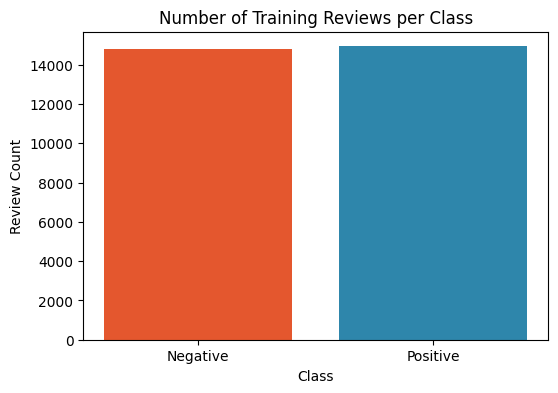

In [5]:
for split_name, split_df in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    print(split_name, split_df["sentiment"].value_counts().to_dict())

counts = train_df["label"].value_counts().sort_index()
plt.figure(figsize=(6, 4))
plt.bar(CLASS_NAMES, counts.values, color=["#E4572E", "#2E86AB"])
plt.title("Number of Training Reviews per Class")
plt.xlabel("Class")
plt.ylabel("Review Count")
plt.show()

# Show one review of every class

In [6]:
for label_idx, class_name in enumerate(CLASS_NAMES):
    example = train_df[train_df["label"] == label_idx].iloc[0]["review"]
    print(class_name, ":", example[:300], "...\n")

Negative : Wow. This was probably the worst DCOM ever. I watched the first half hour and I laughed. Brenda Song plays Wendy, the popular girl with the hot jock boyfriend and stuck up friends who is determined to be Homecoming Queen. She is supposed to save the world as a warrior, and Shin comes to her aid to h ...

Positive : the film itself is absolutely brilliant, its that buzz, that rush that makes you just want to go out, blow your wages and loose yourself. It's what the weekend is all about, its our sanitation where we can come together as one and be ourselves without a care in the world. The film is layered in dept ...



# Text preprocessing (clean_review)
Removes HTML tags, lowercases, expands contractions, removes punctuation and numbers, and removes stopwords. The negations `not`, `no` and `nor` are kept.

In [7]:
import re
import nltk
from nltk.corpus import stopwords

try:
    _english_stopwords = stopwords.words("english")
except LookupError:
    nltk.download("stopwords")
    _english_stopwords = stopwords.words("english")

KEEP_WORDS = {"not", "nor", "no"}
STOP_WORDS = set(_english_stopwords) - KEEP_WORDS


def clean_review(review):
    text = re.sub(r"<.*?>", " ", review)
    text = text.lower()
    text = (text.replace("won't", "will not")
                .replace("can't", "can not")
                .replace("n't", " not"))
    text = re.sub(r"[^a-z ]", " ", text)
    words = text.split()
    return " ".join(w for w in words if w not in STOP_WORDS)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [8]:
print(clean_review("This movie wasn't good.The acting was GREAT!!! <br />Loved it, 10/10."))

movie not good acting great loved


# Clean the text

In [9]:
train_df["clean"] = train_df["review"].apply(clean_review)
val_df["clean"] = val_df["review"].apply(clean_review)
test_df["clean"] = test_df["review"].apply(clean_review)

print("Before:", train_df["review"].iloc[0][:200])
print("After: ", train_df["clean"].iloc[0][:200])

Before: Wow. This was probably the worst DCOM ever. I watched the first half hour and I laughed. Brenda Song plays Wendy, the popular girl with the hot jock boyfriend and stuck up friends who is determined to
After:  wow probably worst dcom ever watched first half hour laughed brenda song plays wendy popular girl hot jock boyfriend stuck friends determined homecoming queen supposed save world warrior shin comes ai


# TF-IDF features (fit on train only)

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

y_train, y_val, y_test = train_df["label"], val_df["label"], test_df["label"]

tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=2)
X_train_vec = tfidf.fit_transform(train_df["clean"])
X_val_vec = tfidf.transform(val_df["clean"])
X_test_vec = tfidf.transform(test_df["clean"])

print("TF-IDF vocabulary size (number of features):", len(tfidf.get_feature_names_out()))
print("X_train_vec shape:", X_train_vec.shape)
print("X_val_vec shape:", X_val_vec.shape)
print("X_test_vec shape:", X_test_vec.shape)

TF-IDF vocabulary size (number of features): 20000
X_train_vec shape: (29748, 20000)
X_val_vec shape: (9917, 20000)
X_test_vec shape: (9917, 20000)


# Logistic Regression

In [11]:
from sklearn.linear_model import LogisticRegression

C_values = [0.01, 0.1, 1, 10, 100]
best_c_lr = None
best_val_f1_lr = 0

print("Tuning Logistic Regression (C):")
for c in C_values:
    lr = LogisticRegression(C=c, max_iter=1000, random_state=RANDOM_STATE)
    lr.fit(X_train_vec, y_train)

    val_preds = lr.predict(X_val_vec)
    val_acc = accuracy_score(y_val, val_preds)
    val_f1 = f1_score(y_val, val_preds, average="macro")
    print(f"C = {c:<6} -> Validation Accuracy: {val_acc:.4f} | Validation Macro-F1: {val_f1:.4f}")

    if val_f1 > best_val_f1_lr:
        best_val_f1_lr = val_f1
        best_c_lr = c

print(f"\nBest C for Logistic Regression: {best_c_lr} | Validation Macro-F1: {best_val_f1_lr:.4f}")

best_lr = LogisticRegression(C=best_c_lr, max_iter=1000, random_state=RANDOM_STATE)
best_lr.fit(X_train_vec, y_train)

Tuning Logistic Regression (C):
C = 0.01   -> Validation Accuracy: 0.8247 | Validation Macro-F1: 0.8242
C = 0.1    -> Validation Accuracy: 0.8679 | Validation Macro-F1: 0.8678
C = 1      -> Validation Accuracy: 0.8972 | Validation Macro-F1: 0.8972
C = 10     -> Validation Accuracy: 0.9002 | Validation Macro-F1: 0.9002
C = 100    -> Validation Accuracy: 0.8918 | Validation Macro-F1: 0.8918

Best C for Logistic Regression: 10 | Validation Macro-F1: 0.9002


LogisticRegression(C=10, max_iter=1000, random_state=42)

In [12]:
lr_test_pred = best_lr.predict(X_test_vec)

lr_test_acc = accuracy_score(y_test, lr_test_pred)
lr_test_f1 = f1_score(y_test, lr_test_pred, average="macro")
print("Test Accuracy:", round(lr_test_acc, 4))
print("Test Macro-F1:", round(lr_test_f1, 4))

Test Accuracy: 0.9004
Test Macro-F1: 0.9004


# Linear SVM

In [13]:
from sklearn.svm import LinearSVC

C_values_svm = [0.01, 0.1, 1, 10]
best_c_svm = None
best_val_f1_svm = 0

print("Tuning Linear SVM (C):")
for c in C_values_svm:
    svm = LinearSVC(C=c, max_iter=5000, random_state=RANDOM_STATE)
    svm.fit(X_train_vec, y_train)

    val_preds = svm.predict(X_val_vec)
    val_acc = accuracy_score(y_val, val_preds)
    val_f1 = f1_score(y_val, val_preds, average="macro")
    print(f"C = {c:<6} -> Validation Accuracy: {val_acc:.4f} | Validation Macro-F1: {val_f1:.4f}")

    if val_f1 > best_val_f1_svm:
        best_val_f1_svm = val_f1
        best_c_svm = c

print(f"\nBest C for Linear SVM: {best_c_svm} | Validation Macro-F1: {best_val_f1_svm:.4f}")

best_svm = LinearSVC(C=best_c_svm, max_iter=5000, random_state=RANDOM_STATE)
best_svm.fit(X_train_vec, y_train)

Tuning Linear SVM (C):
C = 0.01   -> Validation Accuracy: 0.8676 | Validation Macro-F1: 0.8674
C = 0.1    -> Validation Accuracy: 0.8997 | Validation Macro-F1: 0.8996
C = 1      -> Validation Accuracy: 0.8973 | Validation Macro-F1: 0.8973
C = 10     -> Validation Accuracy: 0.8787 | Validation Macro-F1: 0.8787

Best C for Linear SVM: 0.1 | Validation Macro-F1: 0.8996


LinearSVC(C=0.1, max_iter=5000, random_state=42)

In [14]:
svm_test_pred = best_svm.predict(X_test_vec)

svm_test_acc = accuracy_score(y_test, svm_test_pred)
svm_test_f1 = f1_score(y_test, svm_test_pred, average="macro")
print("Test Accuracy:", round(svm_test_acc, 4))
print("Test Macro-F1:", round(svm_test_f1, 4))

Test Accuracy: 0.9012
Test Macro-F1: 0.9011


# Model selection (validation only)

In [15]:
if best_val_f1_lr >= best_val_f1_svm:
    best_name = "Logistic Regression"
    best_model = best_lr
else:
    best_name = "Linear SVM"
    best_model = best_svm

print(f"Selected model (by validation Macro-F1): {best_name}")

Selected model (by validation Macro-F1): Logistic Regression


# Confusion matrix for Logistic Regression and Linear SVM

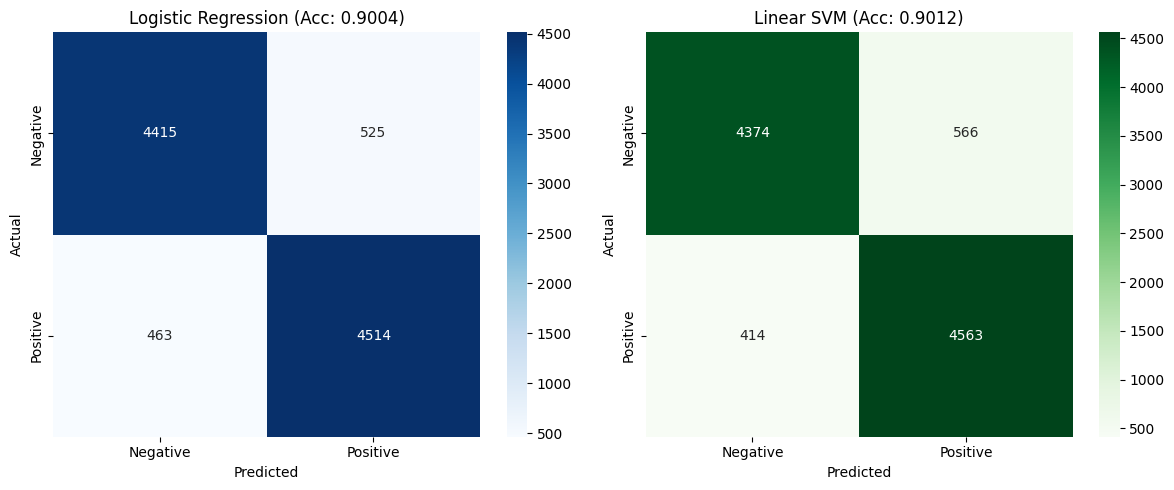

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(confusion_matrix(y_test, lr_test_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0])
axes[0].set_title(f"Logistic Regression (Acc: {lr_test_acc:.4f})")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(confusion_matrix(y_test, svm_test_pred), annot=True, fmt="d", cmap="Greens",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[1])
axes[1].set_title(f"Linear SVM (Acc: {svm_test_acc:.4f})")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

# Precision, Recall and F1 per class

In [17]:
for name, model in [("Logistic Regression", best_lr), ("Linear SVM", best_svm)]:
    print(name)
    print("Validation set")
    print(classification_report(y_val, model.predict(X_val_vec), target_names=CLASS_NAMES, digits=4))
    print("Test set")
    print(classification_report(y_test, model.predict(X_test_vec), target_names=CLASS_NAMES, digits=4))

Logistic Regression
Validation set
              precision    recall  f1-score   support

    Negative     0.9067    0.8913    0.8989      4940
    Positive     0.8939    0.9090    0.9014      4977

    accuracy                         0.9002      9917
   macro avg     0.9003    0.9001    0.9002      9917
weighted avg     0.9003    0.9002    0.9002      9917

Test set
              precision    recall  f1-score   support

    Negative     0.9051    0.8937    0.8994      4940
    Positive     0.8958    0.9070    0.9014      4977

    accuracy                         0.9004      9917
   macro avg     0.9004    0.9003    0.9004      9917
weighted avg     0.9004    0.9004    0.9004      9917

Linear SVM
Validation set
              precision    recall  f1-score   support

    Negative     0.9129    0.8828    0.8976      4940
    Positive     0.8874    0.9164    0.9017      4977

    accuracy                         0.8997      9917
   macro avg     0.9001    0.8996    0.8996      9917
weig

# Error analysis

In [18]:
errors = test_df[["review", "label"]].copy()
errors["predicted"] = best_model.predict(X_test_vec)
wrong = errors[errors["label"] != errors["predicted"]]
print(f"Misclassified: {len(wrong)} of {len(errors)}")

for _, row in wrong.sample(min(5, len(wrong)), random_state=1).iterrows():
    print("Actual:", CLASS_NAMES[row["label"]], "| Predicted:", CLASS_NAMES[row["predicted"]])
    print(row["review"][:400], "...\n")

Misclassified: 988 of 9917
Actual: Negative | Predicted: Positive
Most of what has been said about the negative aspects of the film hold true.<br /><br />BUT .... If I have to sit through a movie were the:<br /><br />Director<br /><br />Director of Photography<br /><br />Editor<br /><br />Can't EVEN miss the darn Microphone Boom popping in and out of the movie for almost every Chapter of the movie, how can I enjoy and concentrate on the story as well as believe  ...

Actual: Positive | Predicted: Negative
Madonna gets into action, again and she fails again! Who's That Girl was released just one year after the huge flop of Shangai Surprise and two after the successful cult movie Desperately seeking Susan. She chose to act in it to forget the flop of the previous movie, not suspecting that this latter could be a flop, too. The movie received a bad acceptance by American critic and audience, while in  ...

Actual: Positive | Predicted: Negative
This is one of those movies that make better

# Ensemble Model (Voting & Stacking)

                 Model  Test Accuracy  Test Macro-F1
   Logistic Regression         0.9004         0.9004
            Linear SVM         0.9012         0.9011
Voting Ensemble (Hard)         0.9021         0.9021
     Stacking Ensemble         0.9035         0.9035


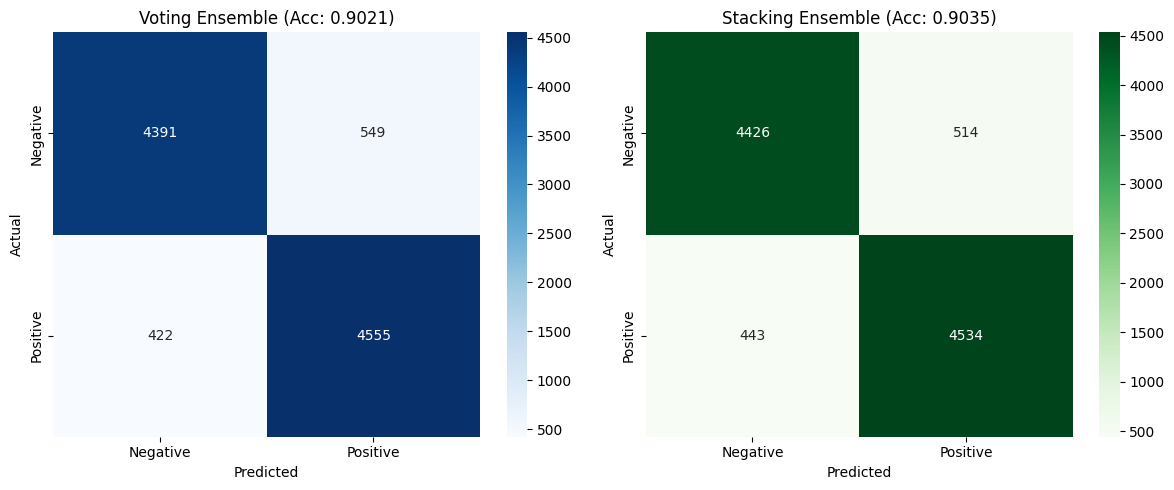

In [19]:
from sklearn.ensemble import VotingClassifier, StackingClassifier
from sklearn.naive_bayes import MultinomialNB

estimators = [
    ("lr", best_lr),
    ("svm", best_svm),
    ("nb", MultinomialNB())
]

voting_clf = VotingClassifier(estimators=estimators, voting="hard")
voting_clf.fit(X_train_vec, y_train)
voting_test_pred = voting_clf.predict(X_test_vec)
voting_test_acc = accuracy_score(y_test, voting_test_pred)

stacking_clf = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    cv=5
)
stacking_clf.fit(X_train_vec, y_train)
stacking_test_pred = stacking_clf.predict(X_test_vec)
stacking_test_acc = accuracy_score(y_test, stacking_test_pred)

results_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Linear SVM",
        "Voting Ensemble (Hard)",
        "Stacking Ensemble"
    ],
    "Test Accuracy": [
        lr_test_acc,
        svm_test_acc,
        voting_test_acc,
        stacking_test_acc
    ],
    "Test Macro-F1": [
        lr_test_f1,
        svm_test_f1,
        f1_score(y_test, voting_test_pred, average="macro"),
        f1_score(y_test, stacking_test_pred, average="macro")
    ]
})

print(results_df.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(confusion_matrix(y_test, voting_test_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0])
axes[0].set_title(f"Voting Ensemble (Acc: {voting_test_acc:.4f})")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(confusion_matrix(y_test, stacking_test_pred), annot=True, fmt="d", cmap="Greens",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[1])
axes[1].set_title(f"Stacking Ensemble (Acc: {stacking_test_acc:.4f})")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

## Model Evaluation & Comparison Summary

### 1. Final Test Results (9,917 Test Samples)

| Model | Key Hyperparameters | Validation Macro-F1 | Test Accuracy | Misclassified Samples |
| :--- | :--- | :---: | :---: | :---: |
| **Logistic Regression** | `C=10` | 0.9002 | **0.9004** | 988 / 9917 |
| **Linear SVM** | `C=0.1` | 0.8996 | **0.9012** | 980 / 9917 |
| **Voting Ensemble (Hard)** | `LR + SVM + Naive Bayes` | — | run the ensemble cell | — |
| **Stacking Ensemble** | `LR + SVM + Naive Bayes` (Meta: `LR`, `cv=5`) | — | run the ensemble cell | — |

### 2. Key Observations & Analysis

* **Effect of `C` (Logistic Regression):** At `C=0.01` the model is strongly regularized and underfits (`0.8242` validation Macro-F1). The score rises to its peak at `C=10` (`0.9002`) and drops slightly at `C=100` (`0.8918`).
* **Effect of `C` (Linear SVM):** The SVM peaks at a small `C=0.1` (`0.8996`) and falls to `0.8787` at `C=10`. With 20,000 features and about 30,000 training reviews, a large `C` lets the model fit noise in the training data.
* **Model comparison:** The two models are practically equal. Logistic Regression is ahead by 0.0006 on validation, and the SVM is ahead by 8 reviews on the test set. The model was selected on validation only.
* **Where the models make mistakes:** TF-IDF counts words and short phrases but does not understand structure. Reviews that turn with "but", sarcasm and mixed opinions are mistaken for the opposite class.
* **Ensemble Performance (`Voting` & `Stacking`):** Write here whether the ensembles improved on the base models and why, after you run the ensemble cell.


# Save the model and vectorizer

In [20]:
import os
import joblib
from google.colab import files

output_dir = "Models"
os.makedirs(output_dir, exist_ok=True)

imdb_model_bundle = {
    "best_model": best_model,
    "tfidf_vectorizer": tfidf,
    "class_names": CLASS_NAMES,
    "lr_model": best_lr,
    "svm_model": best_svm
}

saved_file_path = os.path.join(output_dir, "imdb_sentiment_pipeline.pkl")
joblib.dump(imdb_model_bundle, saved_file_path)

files.download(saved_file_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>